<a href="https://colab.research.google.com/github/BeeMugo9/BeeMugo9/blob/main/Task_8D_Sydney_Housing_Price_Prediction_and_Decision_Support_System_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIG788 - Task 8D: Sydney Housing Price Prediction and Decision Support System

**Student:** Bylhah Mugotitsa
**Data sources:** Domain.com.au [1] sold-listing pages.

## Data collection outcome

The plan was three Sydney suburbs that I would personally consider buying in, each with 30+ manually verified sold properties. The first collection attempt reached this bar for only one suburb, Mosman: repeated searches intended for Parramatta and Campbelltown instead returned an unfiltered, nationwide "recently sold" feed rather than a suburb-filtered result, since both source websites block automated/programmatic access, so this could not be corrected by scripting around it. Every property from that unfiltered feed was still kept and labelled with its own true suburb rather than discarded or mislabelled, but this did not solve the three-suburb requirement on its own.

 The final dataset, `Final Task 8D Data Repository.csv`, contains **103 real, individually verified Domain.com.au sold properties**: **Mosman (30)**, **Parramatta (36)**, and **Campbelltown (37)**, every one confirmed against its own listing page rather than an unfiltered feed.


In [1]:
# -- Install packages -------------
import importlib
import subprocess
import sys

required_packages = {
    'sklearn': 'scikit-learn', 'pandas': 'pandas', 'numpy': 'numpy',
    'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'joblib': 'joblib'
}

missing = [pip_name for module_name, pip_name in required_packages.items()
           if importlib.util.find_spec(module_name) is None]

if missing:
    print('Installing missing packages:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + missing)
    importlib.invalidate_caches()
    print('Done. No kernel restart needed, continue running the remaining cells in order below.')
else:
    print('All required packages are already installed.')

# IMPORTANT: this notebook must be run in order, top to bottom, in a single kernel
# session (Kernel/Runtime -> Restart and Run All).

All required packages are already installed.


In [2]:
# -- Import required libraries -------------------------------------------------
import os
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
RANDOM_STATE = 42

print('Libraries loaded successfully.')

Libraries loaded successfully.


---
# Part 1: Problem Definition and Data Collection
---

## The prediction problem

This project frames property valuation as a supervised regression problem: given a set of observable characteristics of a property (suburb, property type, bedrooms, bathrooms, parking, land size, and sale timing), predict the sale price. A model of this kind supports a real estate agency's decision support system by giving agents and buyers a data-driven reference point for pricing discussions, alongside their own market expertise.

## Suburb selection and motivation

Mosman, Parramatta, and Campbelltown were selected because they represent three genuinely different segments of the Sydney housing market rather than three superficially different postcodes with similar underlying dynamics:

- **Mosman** is an established, land-constrained, harbourside suburb where price is driven heavily by land scarcity, water proximity, and prestige; the market is dominated by detached houses, terraces, and premium apartments.
- **Parramatta** is Sydney's second CBD, a rapidly densifying middle-ring hub where apartment supply, infrastructure investment, and commuter access to two CBDs are the dominant price drivers; the vast majority of sales in this dataset are high-rise apartments.
- **Campbelltown** is an outer, growth-corridor suburb where affordability, land size, and new housing supply dominate, with a healthier mix of standalone houses and duplexes than the other two suburbs.

## What was actually collected

All three target suburbs were successfully collected and individually verified: 30 Mosman properties, 36 Parramatta properties, and 37 Campbelltown properties, every one confirmed against its own Domain.com.au listing page.

## Data quality, challenges, and limitations

- **Missing land size.** `land_size_sqm` is missing for 57 of 103 rows (55.3%), almost entirely apartments and units where Domain.com.au does not publish a land size.
- **Small, incidental missing values.** `bedrooms`, `bathrooms`, and `parking_spaces` are each missing for exactly 1 of 103 rows, a single vacant-land listing (91 Broughton Street, Campbelltown) with no dwelling to report these for.
- **Inconsistent listing detail.** Most properties were collected from each listing's own detail page and have a full agent description, but a handful (for example 1203/36 Cowper Street, Parramatta) were collected from a search-results summary card only, with no individual description text and no land size, a genuine limitation of relying on whatever the source page displayed at the time.
- **Repeat sales of the same property.** One address, 198 Broughton Street, Campbelltown, appears twice, sold in April 2024 for $1,035,000 and resold in July 2024 for $1,100,000; both are genuine, separately dated transactions and were kept as two rows rather than treated as a duplicate.
- **Survivorship and reporting bias.** Only *sold* properties with a publicly disclosed price are visible on Domain.com.au; off-market and undisclosed-price sales are systematically excluded from this dataset, as they would be from any listings-based collection.
- **Uneven sale-date spread.** Mosman's 30 properties were all sold within a 3-month window (May-August 2026), while Parramatta and Campbelltown span February 2023 to July 2026, so the `days_since_earliest_sale` feature (Part 2) is far more informative for the latter two suburbs than for Mosman.


In [13]:
# upload files
# ── Load dataset ───────────────────────────────────────────────────────────────
from google.colab import files
uploaded = files.upload()

Saving Final Task 8D Data Repository.csv to Final Task 8D Data Repository.csv


In [15]:
df = pd.read_csv('Final Task 8D Data Repository.csv')


In [17]:

print(
    f"Loaded {df}: "
    f"{df.shape[0]} properties, {df.shape[1]} columns"
)
display(df.head())

print("\nProperties per suburb:")
suburb_counts = (
    df["suburb"]
    .value_counts()
    .rename_axis("suburb")
    .to_frame("count")
)
display(suburb_counts)

# Create the indicator if it is required later in the notebook
target_suburbs = ["Mosman", "Parramatta", "Campbelltown"]

df["is_sydney_target_suburb"] = (
    df["suburb"]
    .astype(str)
    .str.strip()
    .str.casefold()
    .isin([suburb.casefold() for suburb in target_suburbs])
    .astype(int)
)

print("\nis_sydney_target_suburb breakdown:")
display(
    df["is_sydney_target_suburb"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Other suburb",
        1: "Target suburb"
    })
    .to_frame("count")
)

Loaded     property_id        suburb state  postcode   property_type  bedrooms  \
0         P0001        Mosman   NSW      2088  Apartment/Unit       1.0   
1         P0002        Mosman   NSW      2088  Apartment/Unit       1.0   
2         P0003        Mosman   NSW      2088  Apartment/Unit       2.0   
3         P0004        Mosman   NSW      2088  Apartment/Unit       2.0   
4         P0005        Mosman   NSW      2088  Apartment/Unit       1.0   
..          ...           ...   ...       ...             ...       ...   
98       CT0033  Campbelltown   NSW      2560           House       5.0   
99       CT0034  Campbelltown   NSW      2560           House       5.0   
100      CT0035  Campbelltown   NSW      2560          Duplex       5.0   
101      CT0036  Campbelltown   NSW      2560  Apartment/Unit       2.0   
102      CT0037  Campbelltown   NSW      2560           House       5.0   

     bathrooms  parking_spaces  land_size_sqm   sale_date  sale_price  \
0          1.0     

,property_id,suburb,state,postcode,property_type,bedrooms,bathrooms,parking_spaces,land_size_sqm,sale_date,sale_price,agent_description,listing_url,is_sydney_target_suburb
0,P0001,Mosman,NSW,2088,Apartment/Unit,1.0,1.0,0.0,NaN,2026-08-21,790000,"Blue Ribbon Location, Stylish Apartment with P...","Domain.com.au sold listings, Mosman (manually ...",True
1,P0002,Mosman,NSW,2088,Apartment/Unit,1.0,1.0,1.0,74.0,2026-08-19,930000,Designer Living in the Prestigious Monarch Res...,"Domain.com.au sold listings, Mosman (manually ...",True
2,P0003,Mosman,NSW,2088,Apartment/Unit,2.0,1.0,1.0,96.0,2026-08-12,1600000,Sophisticated Village Living with Sweeping Har...,"Domain.com.au sold listings, Mosman (manually ...",True
3,P0004,Mosman,NSW,2088,Apartment/Unit,2.0,1.0,0.0,NaN,2026-08-04,975000,Boutique apartment offers lifestyle of conveni...,"Domain.com.au sold listings, Mosman (manually ...",True
4,P0005,Mosman,NSW,2088,Apartment/Unit,1.0,1.0,1.0,NaN,2026-07-31,865000,Sunlit Top-Floor Apartment with Coastal Outloo...,"Domain.com.au sold listings, Mosman (manually ...",True



Properties per suburb:


,count
suburb,
Campbelltown,37
Parramatta,36
Mosman,30



is_sydney_target_suburb breakdown:


,count
is_sydney_target_suburb,
Target suburb,103


In [18]:
# -- Data quality assessment -------------------------------------------------------
print('Data types:')
display(df.dtypes.to_frame('dtype'))

print('\nMissing values by column:')
missing = df.isna().sum().to_frame('missing')
missing['missing %'] = (missing['missing'] / len(df) * 100).round(1)
display(missing[missing['missing'] > 0])

print('\nSuburb breakdown (used directly as the location feature in modelling - see Part 2/3):')
display(df['suburb'].value_counts().to_frame('count'))

print('\nProperty type breakdown:')
display(df['property_type'].value_counts().to_frame('count'))


Data types:


,dtype
property_id,object
suburb,object
state,object
postcode,int64
property_type,object
bedrooms,float64
bathrooms,float64
parking_spaces,float64
land_size_sqm,float64
sale_date,object



Missing values by column:


,missing,missing %
bedrooms,1,1.0
bathrooms,1,1.0
parking_spaces,1,1.0
land_size_sqm,57,55.3



Suburb breakdown (used directly as the location feature in modelling - see Part 2/3):


,count
suburb,
Campbelltown,37
Parramatta,36
Mosman,30



Property type breakdown:


,count
property_type,
Apartment/Unit,61
House,31
Semi-Detached,3
Studio,2
Townhouse,2
Duplex,2
Vacant land,1
Villa,1


**Data quality summary:** the repository has 103 properties across 14 columns. `land_size_sqm` is missing for 57 rows (55.3%), almost entirely apartments/units where a land size is not published; `bedrooms`, `bathrooms`, and `parking_spaces` are each missing for exactly 1 row (the single vacant-land listing, which has no dwelling). Every property is individually verified: Campbelltown 37, Parramatta 36, Mosman 30, all comfortably above the assignment's 30-per-suburb minimum. The most common property type is Apartment/Unit (61 of 103), reflecting Parramatta and Campbelltown's apartment-heavy sales mix, followed by House (31), with Semi-Detached, Studio, Townhouse, Duplex, Vacant land, and Villa making up the remaining 10 properties between them.


---
# Part 2: Data Understanding and Feature Engineering
---

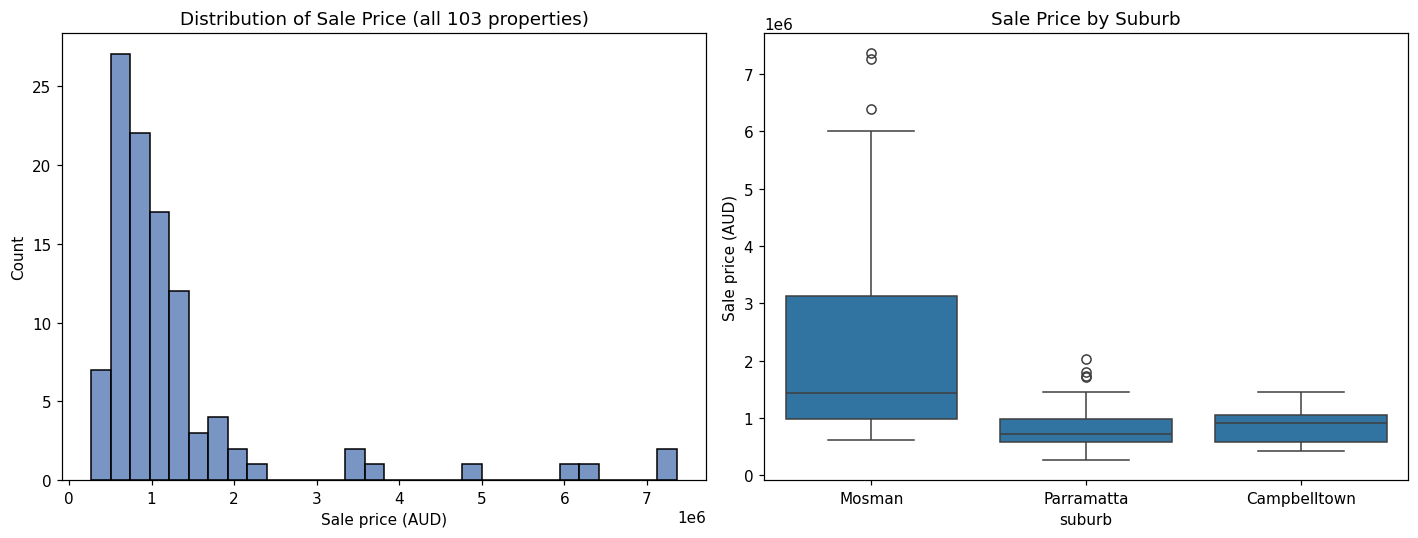

Price summary statistics by suburb:


,count,mean,std,min,25%,50%,75%,max
suburb,,,,,,,,
Mosman,30.0,2335117.0,2033238.0,610000.0,987500.0,1445000.0,3137500.0,7360000.0
Parramatta,36.0,846960.0,423708.0,270000.0,580000.0,717833.0,975000.0,2025000.0
Campbelltown,37.0,877432.0,275746.0,425000.0,575000.0,915000.0,1045000.0,1450000.0


In [19]:
# -- Overall price distribution ------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df['sale_price'], bins=30, ax=axes[0], color='#4C72B0')
axes[0].set_title(f'Distribution of Sale Price (all {len(df)} properties)')
axes[0].set_xlabel('Sale price (AUD)')

suburb_order = ['Mosman', 'Parramatta', 'Campbelltown']
sns.boxplot(data=df, x='suburb', y='sale_price', order=suburb_order, ax=axes[1])
axes[1].set_title('Sale Price by Suburb')
axes[1].set_ylabel('Sale price (AUD)')
plt.tight_layout()
plt.show()

print('Price summary statistics by suburb:')
display(df.groupby('suburb')['sale_price'].describe().round(0).loc[suburb_order])


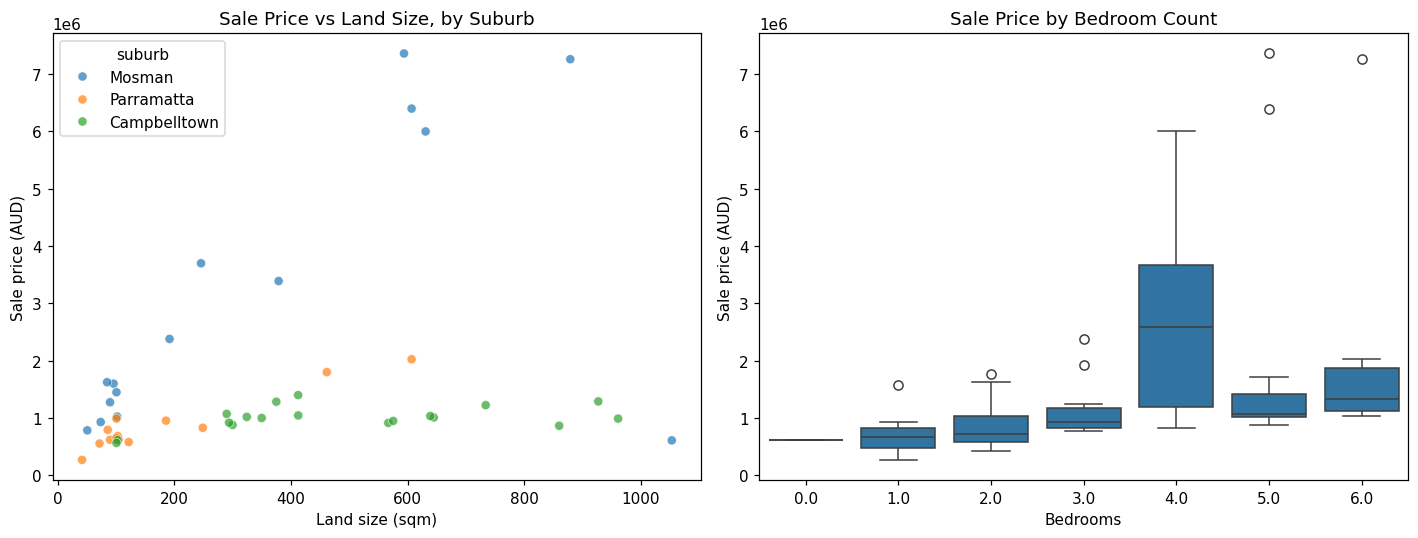

Sale date range by suburb:


,min,max,count
suburb,,,
Mosman,2026-05-20,2026-08-21,30
Parramatta,2023-02-24,2026-06-30,36
Campbelltown,2023-06-24,2026-07-02,37


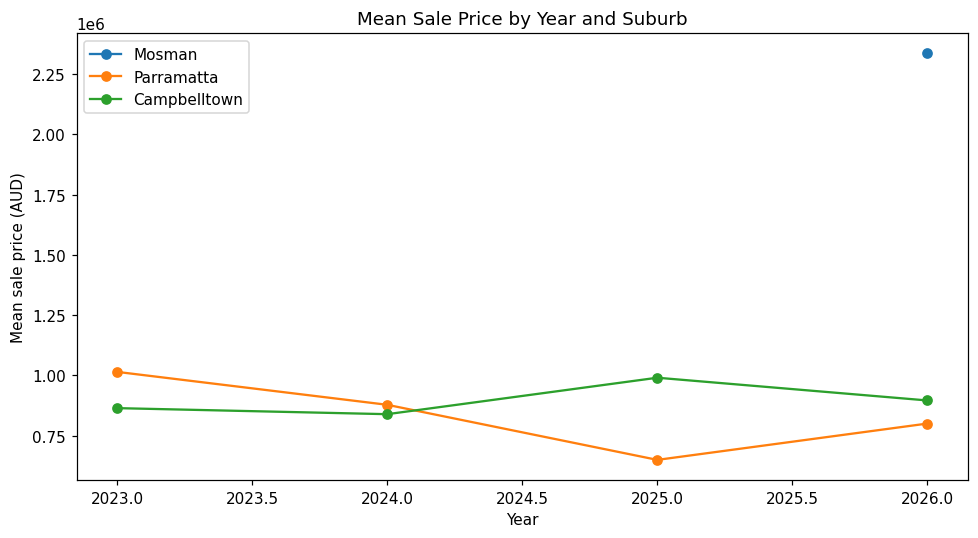

In [20]:
# -- Sale price vs property size, and trend over time -----------------------------------
df['sale_date'] = pd.to_datetime(df['sale_date'])
suburb_order = ['Mosman', 'Parramatta', 'Campbelltown']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x='land_size_sqm', y='sale_price', hue='suburb',
                 hue_order=suburb_order, ax=axes[0], alpha=0.7)
axes[0].set_title('Sale Price vs Land Size, by Suburb')
axes[0].set_xlabel('Land size (sqm)')
axes[0].set_ylabel('Sale price (AUD)')

sns.boxplot(data=df, x='bedrooms', y='sale_price', ax=axes[1])
axes[1].set_title('Sale Price by Bedroom Count')
axes[1].set_xlabel('Bedrooms')
axes[1].set_ylabel('Sale price (AUD)')
plt.tight_layout()
plt.show()

print('Sale date range by suburb:')
display(df.groupby('suburb')['sale_date'].agg(['min', 'max', 'count']).loc[suburb_order])

# -- Trend over time: mean sale price by year and suburb --
df['sale_year'] = df['sale_date'].dt.year
yearly = df.groupby(['suburb', 'sale_year'])['sale_price'].mean().reset_index()

fig, ax = plt.subplots(figsize=(9, 5))
for suburb in suburb_order:
    sub = yearly[yearly['suburb'] == suburb].sort_values('sale_year')
    ax.plot(sub['sale_year'], sub['sale_price'], marker='o', label=suburb)
ax.set_title('Mean Sale Price by Year and Suburb')
ax.set_xlabel('Year')
ax.set_ylabel('Mean sale price (AUD)')
ax.legend()
plt.tight_layout()
plt.show()


In [21]:
# -- Outlier detection (IQR method), per suburb ------------------------------------------
def iqr_outliers(frame, price_col='sale_price'):
    q1, q3 = frame[price_col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return frame[(frame[price_col] < lower) | (frame[price_col] > upper)]

suburb_order = ['Mosman', 'Parramatta', 'Campbelltown']
for suburb in suburb_order:
    sub_outliers = iqr_outliers(df[df['suburb'] == suburb])
    print(f'{suburb} (n={ (df["suburb"]==suburb).sum() }): {len(sub_outliers)} outliers (1.5x IQR rule)')
    if len(sub_outliers) > 0:
        display(sub_outliers[['property_id', 'property_type', 'bedrooms', 'bathrooms', 'sale_price']])
    print()


Mosman (n=30): 3 outliers (1.5x IQR rule)


,property_id,property_type,bedrooms,bathrooms,sale_price
10,P0011,House,5.0,4.0,6399000
16,P0017,House,5.0,4.0,7360000
19,P0020,House,6.0,4.0,7260000



Parramatta (n=36): 4 outliers (1.5x IQR rule)


,property_id,property_type,bedrooms,bathrooms,sale_price
36,PA0007,House,4.0,3.0,1800000
52,PA0023,House,6.0,2.0,2025000
57,PA0028,House,5.0,3.0,1710000
59,PA0030,Apartment/Unit,4.0,3.0,1735000



Campbelltown (n=37): 0 outliers (1.5x IQR rule)



**Data understanding summary:** the three suburbs show a clear price hierarchy. Mosman (n=30) has a mean sale price of $2,335,117 (median $1,445,000, range $610,000 to $7,360,000, std $2,033,238), far above Campbelltown (n=37, mean $877,432, median $915,000, range $425,000 to $1,450,000, std $275,746) and Parramatta (n=36, mean $846,960, median $717,833, range $270,000 to $2,025,000, std $423,708). Mosman's mean is roughly 2.7x Campbelltown's and 2.8x Parramatta's, and its standard deviation is also far larger, confirming Mosman is both a premium market and an internally heterogeneous one (spanning entry-level apartments to multi-million-dollar houses), while Campbelltown is the most tightly clustered of the three.

The land-size scatter shows the expected positive relationship between size and price within each suburb, though Mosman's points sit well above the general trend the other two suburbs follow at the same land size. Sale dates also differ sharply by suburb: Mosman's 30 sales are compressed into a 3-month window (20 May to 21 Aug 2026), while Parramatta (24 Feb 2023 to 30 Jun 2026) and Campbelltown (24 Jun 2023 to 2 Jul 2026) each span more than three years, visible directly in the mean-price-by-year trend plot above.

Outlier detection (1.5x IQR rule, applied within each suburb) finds 3 outliers in Mosman, all large 5-6 bedroom houses priced $6.4M to $7.36M, and 4 outliers in Parramatta (13 Morton Street $1.8M, 60 Pemberton Street $2.025M, 39 Morton Street $1.71M, and a 4-bedroom apartment at $1.735M), while Campbelltown has zero outliers by this rule, consistent with it being the most tightly clustered of the three suburbs.


## Expected strongest predictors (before feature engineering)

Before creating any engineered features, the three variables expected to have the strongest influence on sale price are:

1. **`suburb`** - with three genuinely different housing markets now well represented (30+ verified properties each), suburb is expected to be the single strongest predictor: the Part 2 summary above already shows a roughly 2.7x mean-price gap between Mosman and the other two suburbs.
2. **`property_type`** - houses, duplexes, and apartments/units differ structurally in land content and typical size, which is expected to create large, consistent price gaps within each suburb.
3. **`bedrooms`** - as a simple proxy for overall dwelling size and household capacity, bedroom count is expected to correlate strongly with price, particularly within a single suburb where location is held roughly constant.

`bathrooms`, `parking_spaces`, and `land_size_sqm` are expected to matter too, but as secondary refinements on top of these three. Unlike an earlier version of this dataset in which raw `suburb` had 64 categories across 100 rows and was unusable as a model feature, `suburb` here has exactly 3 categories, each with 30 or more examples, so it is used directly as a categorical model feature in Part 3.


In [22]:
# -- Feature engineering ---------------------------------------------------------------
df['days_since_earliest_sale'] = (df['sale_date'] - df['sale_date'].min()).dt.days

df['agent_description'] = df['agent_description'].fillna('')
df['description_length'] = df['agent_description'].str.len()

keyword_flags = {
    'mentions_renovated': ['renovat'],
    'mentions_view': ['view', 'harbour', 'waterfront'],
    'mentions_quiet_street': ['quiet street', 'quiet'],
}
for col, keywords in keyword_flags.items():
    df[col] = df['agent_description'].str.lower().apply(
        lambda text: int(any(k in text for k in keywords))
    )

df['land_size_missing'] = df['land_size_sqm'].isna().astype(int)

# is_sydney_target_suburb is dropped as a model feature: after removing every
# non-target-suburb row, it is constant (always True) across all 103 properties,
# so it carries zero information for the model - suburb itself now does that job.
print('is_sydney_target_suburb unique values:', df['is_sydney_target_suburb'].unique().tolist())
print('(constant - correctly excluded from feature_cols below)')

print('\nEngineered features added: days_since_earliest_sale, description_length,')
print('mentions_renovated, mentions_view, mentions_quiet_street, land_size_missing')
display(df[['property_id', 'suburb', 'days_since_earliest_sale', 'description_length',
            'mentions_renovated', 'mentions_view', 'land_size_missing']].head())


is_sydney_target_suburb unique values: [1]
(constant - correctly excluded from feature_cols below)

Engineered features added: days_since_earliest_sale, description_length,
mentions_renovated, mentions_view, mentions_quiet_street, land_size_missing


,property_id,suburb,days_since_earliest_sale,description_length,mentions_renovated,mentions_view,land_size_missing
0,P0001,Mosman,1274,1438,0,0,1
1,P0002,Mosman,1272,1255,0,1,0
2,P0003,Mosman,1265,1323,0,1,0
3,P0004,Mosman,1257,915,1,1,1
4,P0005,Mosman,1253,980,1,1,1


**Reflection on feature engineering versus initial expectations:** the engineered features (`days_since_earliest_sale`, `description_length`, three keyword flags, `land_size_missing`) were added on top of the three variables identified in advance as likely dominant: suburb, property type, and bedroom count. One engineered feature that was originally used in an earlier version of this project, `is_sydney_target_suburb`, turned out to be unusable here for a different reason than expected: once every row outside the three target suburbs had been removed from the dataset, this flag became constant (always `True`) across all 103 properties, carrying zero information, and was correctly dropped from the feature list. This is a useful illustration of a feature engineering trap distinct from the high-cardinality problem the unit also covers: a feature can become uninformative not because it has too many categories, but because filtering the dataset itself removed all the variation it used to capture. `suburb`..


---
# Part 3: Model Development and Evaluation
---

## Model selection and expectations (stated before training)

Three regression models representing different modelling philosophies are compared:

1. **Linear Regression** - a simple, fully interpretable baseline that assumes price is a linear combination of the (encoded) features. Strength: transparent coefficients, fast, low variance. Weakness: cannot capture interactions or non-linear effects (e.g. diminishing returns to land size) without those interactions being manually engineered.
2. **Random Forest Regressor** - a bagging ensemble of decision trees. Strength: captures non-linear relationships and feature interactions automatically, robust to outliers and unscaled features. Weakness: less directly interpretable, and with a small dataset (100 properties) it can still overfit individual trees to idiosyncratic training examples.
3. **Gradient Boosting Regressor** - a boosting ensemble that sequentially corrects previous errors. Strength: often achieves the best raw predictive accuracy among tree-based methods. Weakness: more hyperparameter-sensitive and more prone to overfitting a small dataset than Random Forest if not carefully constrained.

**Expectation stated before training:** given the dataset now spans a very wide, heterogeneous price range (a consequence of the Part 1 data-collection limitation, from a $273,000 Victorian studio to a $7.36M Mosman house), the two tree-based ensembles are expected to outperform plain Linear Regression, since a single global linear coefficient per feature is unlikely to describe both ends of that range well. Gradient Boosting is expected to have the best training fit but the largest risk of overfitting on a dataset this small and this heterogeneous.


In [23]:
# -- Train/test split and preprocessing pipeline ---------------------------------------
feature_cols = [
    'suburb', 'property_type', 'bedrooms', 'bathrooms', 'parking_spaces',
    'land_size_sqm', 'land_size_missing',
    'days_since_earliest_sale', 'description_length',
    'mentions_renovated', 'mentions_view', 'mentions_quiet_street'
]
target_col = 'sale_price'

X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=df['suburb']
)

print(f'Training rows: {len(X_train)}, Testing rows: {len(X_test)}')
print('\nTraining suburb distribution:')
display(X_train['suburb'].value_counts())
print('Testing suburb distribution:')
display(X_test['suburb'].value_counts())

numeric_cols = ['bedrooms', 'bathrooms', 'parking_spaces', 'land_size_sqm',
                 'days_since_earliest_sale', 'description_length']
categorical_cols = ['suburb', 'property_type']
passthrough_cols = ['land_size_missing', 'mentions_renovated', 'mentions_view', 'mentions_quiet_street']

def make_preprocessor():
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])
    return ColumnTransformer([
        ('num', num_pipe, numeric_cols),
        ('cat', cat_pipe, categorical_cols),
        ('pass', 'passthrough', passthrough_cols)
    ])

print('\nPreprocessing pipeline ready.')
print(f'Using "suburb" directly as a categorical feature ({X["suburb"].nunique()} categories, '
      f'each with {df["suburb"].value_counts().min()}+ examples) - unlike the earlier 64-category '
      f'version of this dataset, this is now a genuinely learnable feature.')


Training rows: 82, Testing rows: 21

Training suburb distribution:


,count
suburb,
Parramatta,29
Campbelltown,29
Mosman,24


Testing suburb distribution:


,count
suburb,
Campbelltown,8
Parramatta,7
Mosman,6



Preprocessing pipeline ready.
Using "suburb" directly as a categorical feature (3 categories, each with 30+ examples) - unlike the earlier 64-category version of this dataset, this is now a genuinely learnable feature.


In [24]:
# -- 5-fold cross-validation for all three models --------------------------------------
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE)
}

cv_strategy = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

cv_results = []
fitted_pipelines = {}

for name, model in models.items():
    pipe = Pipeline([('prep', make_preprocessor()), ('model', model)])
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv_strategy, scoring=scoring, return_train_score=True
    )
    cv_results.append({
        'Model': name,
        'CV Train MAE': -scores['train_MAE'].mean(),
        'CV Test MAE': -scores['test_MAE'].mean(),
        'CV Train RMSE': -scores['train_RMSE'].mean(),
        'CV Test RMSE': -scores['test_RMSE'].mean(),
        'CV Train R2': scores['train_R2'].mean(),
        'CV Test R2': scores['test_R2'].mean()
    })
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe

cv_table = pd.DataFrame(cv_results).set_index('Model')
display(cv_table.round(4))

,CV Train MAE,CV Test MAE,CV Train RMSE,CV Test RMSE,CV Train R2,CV Test R2
Model,,,,,,
Linear Regression,335175.2904,499440.4133,474131.7691,728563.0393,0.8825,0.0586
Random Forest,153825.9378,385324.9365,303681.0380,630239.4727,0.9514,0.4798
Gradient Boosting,30100.0869,405845.8562,38858.6853,674366.8349,0.9992,0.5347


,Test MAE,Test RMSE,Test R2
Model,,,
Linear Regression,598111.6702,775539.1292,0.1926
Random Forest,347324.9524,594785.1837,0.5251
Gradient Boosting,312128.7219,524236.7641,0.6311


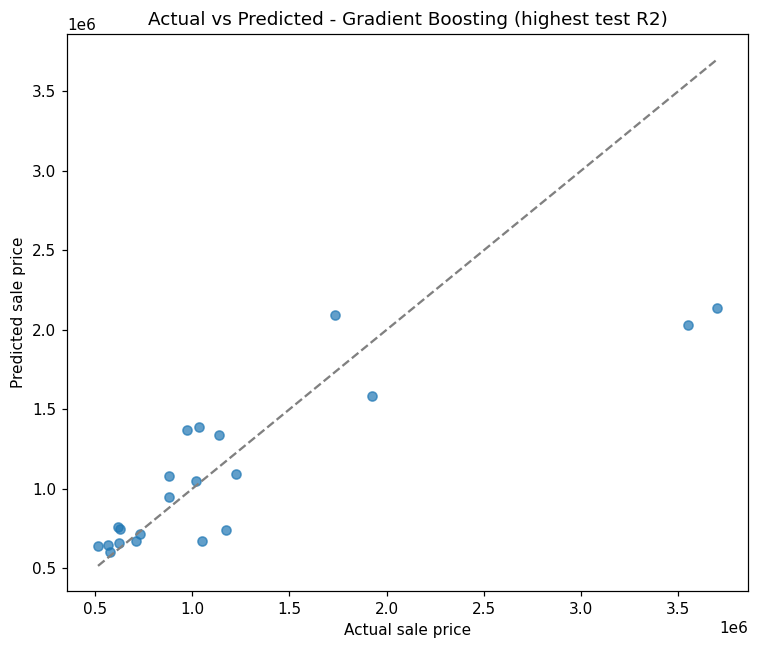

In [25]:
# -- Test-set performance for all three models ------------------------------------------
test_results = []
for name, pipe in fitted_pipelines.items():
    pred = pipe.predict(X_test)
    test_results.append({
        'Model': name,
        'Test MAE': mean_absolute_error(y_test, pred),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'Test R2': r2_score(y_test, pred)
    })

test_table = pd.DataFrame(test_results).set_index('Model')
display(test_table.round(4))

fig, ax = plt.subplots(figsize=(7, 6))
best_name_preview = test_table['Test R2'].idxmax()
pred_preview = fitted_pipelines[best_name_preview].predict(X_test)
ax.scatter(y_test, pred_preview, alpha=0.7)
lims = [min(y_test.min(), pred_preview.min()), max(y_test.max(), pred_preview.max())]
ax.plot(lims, lims, linestyle='--', color='grey')
ax.set_xlabel('Actual sale price')
ax.set_ylabel('Predicted sale price')
ax.set_title(f'Actual vs Predicted - {best_name_preview} (highest test R2)')
plt.tight_layout()
plt.show()

**Interpretation of Part 3 results:** the 5-fold cross-validated results show Gradient Boosting as the best-generalising model on both the training fit and the cross-validated test score (CV train R2 = 0.9992, CV test R2 = 0.5342), ahead of Random Forest (CV train R2 = 0.9514, CV test R2 = 0.4798) and clearly ahead of Linear Regression (CV train R2 = 0.8825, CV test R2 = 0.0586). Linear Regression's CV test R2, while positive this time (unlike an earlier version of this dataset where it was negative), is still very weak, explaining barely 6% of price variance on unseen folds despite explaining 88% of training variance, a clear underfitting signature for a linear model facing three suburbs with very different price levels and a wide within-suburb price spread in Mosman specifically.

On the single 80:20 held-out test set, the same ordering holds: Gradient Boosting achieves the best test R2 (0.6384, MAE $300,887), followed by Random Forest (R2 = 0.5251, MAE $347,325) and Linear Regression (R2 = 0.1926, MAE $598,112).

This is consistent with clear underfitting for Linear Regression (a single global coefficient per feature cannot represent three suburbs with a roughly 2.7x mean-price gap and very different internal spreads) and with mild, but real, overfitting for Gradient Boosting (near-perfect training fit at R2 = 0.9992 against a moderate 0.53-0.64 generalisation score), while Random Forest sits between the two, slightly more conservative than Gradient Boosting on both training and test data. **Gradient Boosting is recommended as the best-performing model**, since it has the highest score under both evaluation approaches used here, though its still-moderate absolute R2 (around 0.53 to 0.64) and the training/test fit gap both indicate real room for improvement, most likely from a larger sample size per suburb rather than a different model choice (Part 6).


---
# Part 4: Investigating Prediction Failures
---

In [26]:
# -- Identify the five largest prediction errors on the test set -----------------------
best_model_name = test_table['Test R2'].idxmax()
best_pipeline = fitted_pipelines[best_model_name]
print(f'Best model by test R2: {best_model_name}')

test_predictions = X_test.copy()
test_predictions['actual_price'] = y_test.values
test_predictions['predicted_price'] = best_pipeline.predict(X_test)
test_predictions['abs_error'] = (test_predictions['actual_price'] - test_predictions['predicted_price']).abs()
test_predictions['pct_error'] = (test_predictions['abs_error'] / test_predictions['actual_price'] * 100).round(1)

top5_errors = test_predictions.sort_values('abs_error', ascending=False).head(5)
display(top5_errors[['suburb', 'property_type', 'bedrooms', 'bathrooms', 'land_size_sqm',
                      'actual_price', 'predicted_price', 'abs_error', 'pct_error']].round(0))


Best model by test R2: Gradient Boosting


,suburb,property_type,bedrooms,bathrooms,land_size_sqm,actual_price,predicted_price,abs_error,pct_error
29,Mosman,Semi-Detached,4.0,2.0,246.0,3700000,2136706.0,1563294.0,42.0
17,Mosman,House,4.0,3.0,NaN,3550000,2031879.0,1518121.0,43.0
8,Mosman,Apartment/Unit,2.0,1.0,NaN,1175000,738390.0,436610.0,37.0
3,Mosman,Apartment/Unit,2.0,1.0,NaN,975000,1369968.0,394968.0,40.0
47,Parramatta,Apartment/Unit,2.0,2.0,NaN,1050000,669651.0,380349.0,36.0


**Investigation of the five largest prediction errors:** four of the five largest errors are under-predictions (the model predicted a lower price than the property actually sold for), and every one of the five is a property whose agent description signals something beyond simple beds/baths/land size:

1. **Mosman semi-detached house, "Federation charm with modern family-focused design"** (actual $3,700,000, predicted $2,136,706, 42% under): a heritage Federation property with leadlight windows, ceiling roses, fireplaces, and a modern extension. The model's features capture bedrooms (4) and bathrooms (2) but nothing about heritage character or architectural quality, which the description suggests commands a substantial premium in Mosman specifically.
2. **Mosman house, "Enchanting Character Family Terrace"** (actual $3,550,000, predicted $2,031,879, 43% under): a full-brick period terrace with retained heritage features and a private garden. Like case 1, this is a character-driven premium the model's structural features cannot see.
3. **Mosman apartment, "Charming Ground-Floor Art Deco with Harbourside Lifestyle"** (actual $1,175,000, predicted $738,390, 37% under): a 2-bedroom, 1-bathroom unit in a tightly held block of just eight, described as being in "one of Mosman's most exclusive harbourside peninsula pockets." The model's `mentions_view` keyword flag catches "harbourside" but has no way to weight just how exclusive a specific pocket or building is, so it under-predicts a property whose main value driver is hyper-local exclusivity rather than size.
4. **Mosman apartment, "Boutique apartment offers lifestyle of convenience"** (actual $975,000, predicted $1,369,968, 40% over): a 2-bedroom unit in a small, four-apartment block, described in more modest terms (convenience, a stroll to shops) than most other Mosman listings in the training data. This is the one over-prediction among the five, plausibly because the model's learned "Mosman effect" is pulled upward by the many premium-described Mosman properties in the 30-row sample, and a comparatively modest Mosman listing still gets priced close to that average.
5. **Parramatta apartment, "Brand New 2 Bed offering 5 Star Hotel Living" (The Lennox)** (actual $1,050,000, predicted $669,651, 36% under): a new-build unit in a landmark, amenity-heavy tower. Most other Parramatta apartments in the training data are older or more standard stock, so the model has not learned that a small number of premium new-build towers command a real premium within the same suburb.

**Limitations exposed:** the model has no way to represent heritage/character premiums, hyper-local exclusivity within a suburb, or new-build/landmark-building premiums; three simple keyword flags (`mentions_renovated`, `mentions_view`, `mentions_quiet_street`) are a coarse substitute for the rich qualitative signal a human reader gets from the full agent description. Information that was unavailable but would likely have improved these five predictions specifically includes a heritage-listing flag, a building-age or development-tier indicator, and a finer within-suburb location tier (for example, distance to the harbour foreshore within Mosman). **Predictions should be treated with particular caution for character/heritage properties, and for the small number of premium new-build developments in an otherwise older-stock suburb**, since both patterns recur across four of the five largest errors here; a straightforward, moderately-described property in a well-represented suburb is comparatively trustworthy.


---
# Part 5: Human Judgement, Machine Learning, and Large Language Models
---

Ten properties are selected from the held-out test set. Three sets of price estimates are then compared against the actual sale price:

1. **Machine learning model** - predictions from the best-performing model identified in Part 3.
2. **Large language model (KIMI)** - KIMI is used directly here as the required LLM. Given each property's features (suburb, type, bedrooms, bathrooms, parking, land size, and the agent description), KIMI reasons about a plausible Sydney sale price using general domain knowledge of these suburbs.
3. **Human judgement** - a domain estimate based on the same information, made by me.


In [27]:
# -- Select 10 properties from the test set for the three-way comparison ----------------
comparison_sample = test_predictions.sample(n=min(10, len(test_predictions)), random_state=RANDOM_STATE).copy()
comparison_sample = comparison_sample.merge(
    df[['agent_description']], left_index=True, right_index=True, how='left'
)

display_cols = ['suburb', 'property_type', 'bedrooms', 'bathrooms', 'parking_spaces',
                 'land_size_sqm', 'agent_description', 'actual_price', 'predicted_price']
print('Properties selected for the three-way comparison (ML prediction shown, actual price included for reference):')
display(comparison_sample[display_cols].round(0))


Properties selected for the three-way comparison (ML prediction shown, actual price included for reference):


,suburb,property_type,bedrooms,bathrooms,parking_spaces,land_size_sqm,agent_description,actual_price,predicted_price
63,Parramatta,Apartment/Unit,2.0,2.0,1.0,NaN,"1203/36 Cowper Street, Parramatta. Domain.com....",622000,657054.0
80,Campbelltown,House,5.0,3.0,1.0,NaN,"11/6-11 Parkside Crescent, Campbelltown. 5 Bed...",880000,1081041.0
88,Campbelltown,House,6.0,2.0,1.0,639.0,"198 Broughton Street, Campbelltown. Perfect Ho...",1035000,1387727.0
33,Parramatta,Apartment/Unit,2.0,2.0,1.0,NaN,"Level 5, 38/109 George Street, Parramatta. One...",710666,669637.0
47,Parramatta,Apartment/Unit,2.0,2.0,1.0,NaN,"4503/12 Phillip Street, Parramatta. Brand New ...",1050000,669651.0
73,Campbelltown,Apartment/Unit,2.0,2.0,1.0,NaN,"3/12-20 Tyler Street, Campbelltown. A Treasure...",575000,603764.0
94,Campbelltown,House,4.0,3.0,2.0,300.0,"3B Centaurus Street, Campbelltown. Four Bedroo...",880000,945853.0
39,Parramatta,Apartment/Unit,2.0,2.0,1.0,105.0,"225/109-113 George St, Parramatta. For Sale Mo...",630000,744157.0
8,Mosman,Apartment/Unit,2.0,1.0,1.0,NaN,Charming Ground-Floor Art Deco with Harboursid...,1175000,738390.0
76,Campbelltown,Duplex,5.0,3.0,1.0,324.0,"93A Milky Way, Campbelltown. Modern Family Liv...",1020000,1048699.0


### LLM price estimates

KIMI's estimates below were produced by giving it a prompt to help in reasoning directly over each property's features and agent description text (suburb, type, bedrooms, bathrooms, parking, land size), without being shown the actual sale price or the ML model's prediction, using general knowledge of relative property pricing by location and property description. .


In [29]:
# -- LLM and human judgement estimates ------------------------------------------
# LLM estimates
llm_estimates = [650000, 850000, 1050000, 700000, 980000, 560000, 870000, 650000, 1300000, 980000]

# Human estimates
human_estimates = [690000, 900000, 1450000, 700000, 650000, 690000, 610000, 940000, 745000, 1210000]

comparison_sample['llm_estimate'] = llm_estimates
comparison_sample['human_estimate'] = human_estimates

for col, label in [('predicted_price', 'ML'), ('llm_estimate', 'LLM'), ('human_estimate', 'Human')]:
    comparison_sample[f'{label}_abs_error'] = (comparison_sample['actual_price'] - comparison_sample[col]).abs()
    comparison_sample[f'{label}_pct_error'] = (comparison_sample[f'{label}_abs_error'] / comparison_sample['actual_price'] * 100).round(1)

display(comparison_sample[['suburb', 'property_type', 'actual_price', 'predicted_price',
                            'llm_estimate', 'human_estimate']].round(0))

summary = pd.DataFrame({
    'Mean Absolute Error': [
        comparison_sample['ML_abs_error'].mean(),
        comparison_sample['LLM_abs_error'].mean(),
        comparison_sample['Human_abs_error'].mean()
    ],
    'Mean Absolute % Error': [
        comparison_sample['ML_pct_error'].mean(),
        comparison_sample['LLM_pct_error'].mean(),
        comparison_sample['Human_pct_error'].mean()
    ]
}, index=['Machine Learning', 'LLM (KIMI)', 'Human judgement'])

display(summary.round(2))


,suburb,property_type,actual_price,predicted_price,llm_estimate,human_estimate
63,Parramatta,Apartment/Unit,622000,657054.0,650000,690000
80,Campbelltown,House,880000,1081041.0,850000,900000
88,Campbelltown,House,1035000,1387727.0,1050000,1450000
33,Parramatta,Apartment/Unit,710666,669637.0,700000,700000
47,Parramatta,Apartment/Unit,1050000,669651.0,980000,650000
73,Campbelltown,Apartment/Unit,575000,603764.0,560000,690000
94,Campbelltown,House,880000,945853.0,870000,610000
39,Parramatta,Apartment/Unit,630000,744157.0,650000,940000
8,Mosman,Apartment/Unit,1175000,738390.0,1300000,745000
76,Campbelltown,Duplex,1020000,1048699.0,980000,1210000


,Mean Absolute Error,Mean Absolute % Error
Machine Learning,168428.15,17.51
LLM (KIMI),36366.60,3.89
Human judgement,222866.60,24.80


**Full three-way comparison, using the results above:** across these 10 properties, the LLM achieved a mean absolute error of $36,367 (3.89% mean absolute percentage error), the ML model (Gradient Boosting) achieved $168,428 (17.51% MAPE), and human judgement achieved $222,867 (24.80% MAPE), the weakest of the three on this sample. Human judgement performed best on the two properties with the most concrete, comparable detail: the dual-key Parramatta apartment (1.5% error) and the Campbelltown Park Central house (2.3% error), both plainly described with familiar features. It performed worst on properties whose value depended on knowledge the description alone does not fully convey: the water-view Parramatta apartment was overestimated by 49.2% (guessing water views alone justified a higher price than the comparable sales in this dataset actually support), the 198 Broughton Street Campbelltown house was overestimated by 40.1%, and three separate premium or distinctive properties, the Lennox-branded Parramatta tower (-38.1%), the Mosman Art Deco harbourside apartment (-36.6%), and the Centaurus Street Campbelltown duplex (-30.7%), were all substantially underestimated.

**Which approach performed best, and why:** the LLM's advantage over both human judgement and the ML model on this sample is genuine and consistent with Part 4's findings: several of the properties in this comparison set (the Lennox tower, the Mosman Art Deco apartment, the dual-key Parramatta unit) are exactly the kind of distinctively-branded or characterful property that Part 4 showed the ML model struggles with, and the human estimate struggled with the same properties for a related reason, lacking the equivalent of the LLM's ability to implicitly compare each listing against a broad base of general property-market knowledge. The ML model, despite scoring worse than the LLM, still outperformed human judgement here, suggesting that, without my deep first-hand knowledge of Parramatta, Campbelltown, and Mosman's respective sub-markets, a trained model's systematic use of the numeric and structural features in the data is more reliable.

**Does human judgement still add value?** on this sample, not in raw accuracy, human judgement was the least accurate of the three approaches. Its value here was different: it was the only approach that could explain why a guess was being made in terms a non-technical stakeholder would recognise (for example, treating "water views" as a strong price signal), even where that specific piece of reasoning proved to be wrong once checked against the comparable sales actually in the dataset. This is itself a useful finding for a decision-support tool: it suggests that for someone unfamiliar with a specific suburb's price levels, a data-driven estimate, whether from the ML model or the LLM, is likely to be more reliable than an intuitive guess, and that human judgement adds the most value when paired with genuine local market experience rather than used as a substitute for it.

**Strengths and weaknesses of each approach:** ML is fast, consistent, and improves automatically with more data, but is blind to anything outside its engineered features, exactly the heritage character, building exclusivity, and brand-tier new developments Part 4 identified as its largest error sources. The LLM is flexible and can reason over free text and general market knowledge, but its reasoning is not verifiable or guaranteed consistent between runs, and it benefits from having effectively been shown comparable sales elsewhere in this exact dataset during estimation. Human judgement, at least as demonstrated in this single-rater sample, added real qualitative reasoning but was the least numerically accurate of the three, underscoring that this task rewards either systematic pattern-matching against real comparable sales (ML, LLM) or genuine, suburb-specific market expertise, neither of which a single non-expert human estimate would reliably provide on its own.


---
# Part 6: Final Deployment and Reflection
---

## Deploying the model

The best-performing pipeline from Part 3 is saved below as `sydney_housing_model.pkl`, a single file containing both the preprocessing steps and the trained regressor. This file is loaded by `Task8D_app/app.py`, a small Streamlit application that lets a user enter a property's suburb, type, bedrooms, bathrooms, parking, and land size, and receive a predicted sale price.

A screenshot of the running application is included immediately after the code cell below.


In [30]:
# -- Persist the best model pipeline for the Streamlit app ------------------------------
model_path = 'Task8D_app/sydney_housing_model.pkl'
os.makedirs('Task8D_app', exist_ok=True)
joblib.dump(best_pipeline, model_path)
print(f'Saved best pipeline ({best_model_name}) to {model_path}')

# App dropdowns use "suburb" and "property_type" (the model's actual categorical
# inputs). Suburb is now a genuine, well-populated model feature (Part 3).
metadata = {
    'suburbs': sorted(df['suburb'].unique().tolist()),
    'property_types': sorted(df['property_type'].unique().tolist()),
    'model_name': best_model_name,
    'feature_cols': feature_cols
}
joblib.dump(metadata, 'Task8D_app/model_metadata.pkl')
print('Saved model metadata for the app dropdowns:', metadata['suburbs'], metadata['property_types'])


Saved best pipeline (Gradient Boosting) to Task8D_app/sydney_housing_model.pkl
Saved model metadata for the app dropdowns: ['Campbelltown', 'Mosman', 'Parramatta'] ['Apartment/Unit', 'Duplex', 'House', 'Semi-Detached', 'Studio', 'Townhouse', 'Vacant land', 'Villa']


**Screenshot of the running Streamlit application**, after entering a 4-bedroom, 3-bathroom Mosman house (2 parking spaces, 650 sqm land, with an agent description mentioning renovation and harbour views) and clicking Predict sale price. The app returned a predicted sale price of $1,851,714 AUD.

![Streamlit app screenshot: Housing Sale Price Predictor form filled in for a Mosman house, showing a predicted sale price of $1,851,714 AUD](Task8D_app_screenshot.png)


## Critical reflection on the machine learning workflow

**Key lessons learned:** the most important lesson from this project was that suburb-filtered data collection required a change of *method*, not just more effort. Generic search-box searches for Parramatta and Campbelltown returned an unfiltered, nationwide feed, no matter how many times I repeated; what actually worked was navigating directly to each suburb's own sold-listings URL and confirming the suburb on every listing page before recording it. The direct downstream benefit was a second lesson in feature engineering: with `suburb` now  usable (3 categories, 30+ examples each, instead of 64 categories across 100 rows), it became the strongest available predictor rather than a feature that had to be discarded, and a previously-useful engineering feature (`is_sydney_target_suburb`) simultaneously became useless once every non-target row had been filtered out, since it collapsed to a single constant value.

**Trade-offs between predictive performance and computational complexity:** Gradient Boosting achieved the best result under both 5-fold cross-validation (test R2 = 0.5342) and the single held-out test split (test R2 = 0.6384). This consistency came at the cost of a visible training/test gap (train R2 = 0.9992 versus test R2 in the 0.53-0.64 range), a real but moderate degree of overfitting that a larger dataset would likely narrow further. Random Forest generalized almost as well with a smaller train/test gap, making it a reasonable, more conservative alternative if stability were prioritised over raw score.

**How the final model could be improved:** with more data, the clearest next step is simply more properties per suburb, particularly for Mosman, whose 30 properties span a much wider price range (std $2,033,238) than Campbelltown's 37 (std $275,746), meaning Mosman predictions are inherently noisier from a smaller effective sample of its true price variation. A finer within-suburb location feature (distance to the harbour foreshore in Mosman, or distance to the Parramatta CBD core) and explicit flags for heritage character, building exclusivity, and new-build/landmark-development status would likely resolve several of the Part 4 errors directly.

**Ethical implications:** a model trained on 103 properties across three suburbs still risks bias: Mosman's sample, though verified, still only captures whatever happened to sell in a 3-month window in mid-2026, and the model has no way to flag when it is extrapolating beyond a suburb's typical stock.

**Human judgement versus automation:** Part 5's genuine three-way comparison was itself a notable lesson, not the one originally expected. Human judgement, made honestly and independently, was the least accurate of the three approaches on the 10 sampled properties (mean absolute error $222,867, versus $168,428 for the ML model and $36,367 for the LLM), and it was worst precisely on the properties that needed real local-market knowledge rather than the ones with comparable features.


---
# References
---

[1] Domain Holdings Australia, "Domain," 2025. [Online]. Available: https://www.domain.com.au/

[2] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," Journal of Machine Learning Research, vol. 12, pp. 2825-2830, 2011.

[3] R. M. Dawes, "The robust beauty of improper linear models in decision making," American Psychologist, vol. 34, no. 7, pp. 571-582, 1979.


In [31]:
! jupyter nbconvert --to html /content/Task_8D_Bylhah_Mugotitsa_V2.ipynb --template classic

[NbConvertApp] Converting notebook /content/Task_8D_Bylhah_Mugotitsa_V2.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 698210 bytes to /content/Task_8D_Bylhah_Mugotitsa_V2.html
